# Qwen TorchAO + sim-pruning: full Trainer-step profiling

Продолжение `qlora-Qwen3-30B-A3B_torchao_simpruning_optimization.ipynb`. Старые эксперименты и результаты сохранены.

GPU 2, FP16 compute / FP32 LoRA, INT4 TorchAO, batch=8, context=512, AdamW. SP: исходный сохранённый план 30% для attention и MLP в слоях 45–47. TL attention, RMSNorm, маски и quantized kernels **не меняются**.

Здесь измеряется настоящий SFTTrainer step, включая FLOP accounting, clipping, optimizer и zero_grad, а не только forward/backward.


In [1]:
from pathlib import Path
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'lora_transfer_pruning').is_dir())
HERE = REPO / 'experiments/qlora'
ROOT = HERE / 'slop_experiments/8_torchao_simpruning_optimization_2/torchao_trainer_overhead'
study = json.loads((ROOT / 'results.json').read_text())
paired = json.loads((ROOT / 'paired_cache/results.json').read_text())
traces = json.loads((ROOT / 'trace_summary.json').read_text())


## 1. Контроли и поиск затрат

По 7 настоящих шагов с одинаковыми начальными LoRA-весами, seed и данными. Для скорости исключены шаги 1–2 и профилируемый шаг 4. `cached_train` — уже проверенная ранее оптимизация повторного `model.train()`.

**Ограничение:** между последовательными сериями менялось время forward; поэтому итоговую прибавку от новых кэшей оцениваем ниже по чередующемуся A/B внутри одного Trainer. Таблица здесь нужна прежде всего для разбивки затрат и контроля TL без масок.


In [2]:
rows = []
for r in study['results']:
    rows.append({'case': r['name'], 'step_s': r['step_s'], 'tokens/s': r['tokens_per_s'],
                 'samples/s': r['tokens_per_s']/512, 'peak_GiB': r['peak_GiB'],
                 **r['phases_s']})
controls = pd.DataFrame(rows).set_index('case')
display(controls.round(4))


,step_s,tokens/s,samples/s,peak_GiB,set_train_mode,prepare_inputs,compute_loss_and_metrics,backward,training_step,flop_counter,gradient_clipping,get_grad_norm,zero_grad
case,,,,,,,,,,,,,
hf_sdpa,5.6521,724.6882,1.4154,26.6038,0.1323,0.0001,4.4000,0.7923,5.3338,0.1279,0.0829,0.0001,0.0746
hf_eager,5.8656,698.3031,1.3639,27.7944,0.1309,0.0001,4.5728,0.8242,5.5421,0.1259,0.0857,0.0001,0.0748
tl_no_sp_cached_train,7.4156,552.3496,1.0788,27.7898,0.0000,0.0000,5.5834,0.8431,6.4384,0.4445,0.2531,0.0001,0.2436
tl_sp_cached_train,7.3271,559.0234,1.0918,27.8043,0.0000,0.0000,5.6074,0.7379,6.3551,0.4400,0.2548,0.0001,0.2425
tl_sp_cached_flops,7.7259,530.1634,1.0355,27.8043,0.0000,0.0001,6.4450,0.7078,7.1679,0.0001,0.2714,0.0001,0.2449
tl_sp_cached_flops_params,7.1885,569.7994,1.1129,27.8043,0.0000,0.0001,6.4053,0.6906,7.1127,0.0001,0.0298,0.0001,0.0045


## 2. Парный A/B: только кэширование обходов

Один Trainer, один набор из 8 блоков текста, чередование **A–B–B–A × 3**, после двух прогревочных шагов. В A уже есть оптимизация `train()`; в B дополнительно кэшируются число параметров для FLOP estimate и список объектов Parameter для clipping/zero_grad. Время включает полный optimizer step.

В этом **скоростном** контроле `lr=0`, чтобы веса оставались одинаковыми; backward, clipping и AdamW всё равно выполняются. Это не кривая сходимости. Реальные обновления и их идентичность проверены отдельно семью шагами с ненулевым LR. Последний, 15-й, шаг записан profiler и исключён из скорости.


,step_s,tokens_per_s,samples_per_s,peak_GiB
baseline,6.3116,648.9646,1.2675,27.7642
cached,5.4082,757.3630,1.4792,27.7645


Throughput improvement: 16.7%
Step time saved: 0.903 s (14.3%)


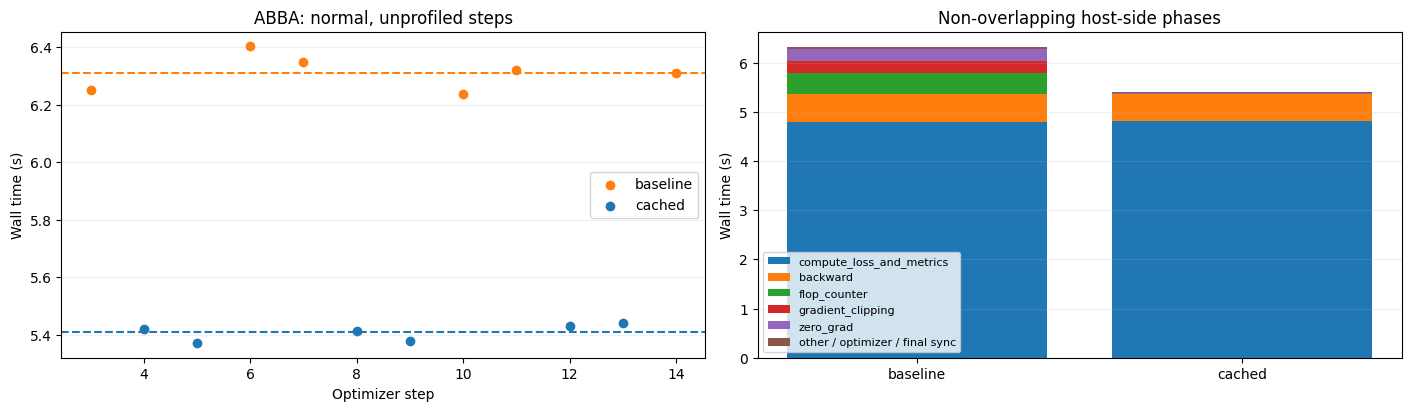

,baseline,cached
get_grad_norm,0.00006,0.00005
gradient_clipping,0.24931,0.01660
backward,0.56907,0.53937
prepare_inputs,0.00004,0.00004
set_train_mode,0.00003,0.00003
flop_counter,0.42727,0.00006
zero_grad,0.24047,0.00322
training_step,5.36727,5.36208
compute_loss_and_metrics,4.78993,4.81421


In [3]:
paired_table = pd.DataFrame(paired['summaries']).T
scalar_columns = ['step_s', 'tokens_per_s', 'samples_per_s', 'peak_GiB']
display(paired_table[scalar_columns].astype(float).round(4))
a, b = paired['summaries']['baseline'], paired['summaries']['cached']
print(f"Throughput improvement: {100*(b['tokens_per_s']/a['tokens_per_s']-1):.1f}%")
print(f"Step time saved: {a['step_s']-b['step_s']:.3f} s ({100*(1-b['step_s']/a['step_s']):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for name, color in [('baseline', 'tab:orange'), ('cached', 'tab:blue')]:
    rows = [r for r in paired['steps'] if paired['schedule'][r['step']-1] == name]
    axes[0].scatter([r['step'] for r in rows], [r['step_seconds'] for r in rows], label=name, color=color)
    axes[0].axhline(paired['summaries'][name]['step_s'], color=color, linestyle='--')
axes[0].set(xlabel='Optimizer step', ylabel='Wall time (s)', title='ABBA: normal, unprofiled steps')
axes[0].legend()
keys = ['compute_loss_and_metrics', 'backward', 'flop_counter', 'gradient_clipping', 'zero_grad']
bottom = np.zeros(2)
for key in keys:
    values = np.array([paired['summaries'][name]['phases_s'][key] for name in ['baseline', 'cached']])
    axes[1].bar(['baseline', 'cached'], values, bottom=bottom, label=key)
    bottom += values
other = np.array([a['step_s'], b['step_s']]) - bottom
axes[1].bar(['baseline', 'cached'], other, bottom=bottom, label='other / optimizer / final sync')
axes[1].set(ylabel='Wall time (s)', title='Non-overlapping host-side phases')
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(axis='y', alpha=.2)
plt.show()
display(pd.DataFrame({k:v['phases_s'] for k,v in paired['summaries'].items()}).round(5))


## 3. Проверка корректности

При настоящем обучении (7 шагов, одинаковые seed, batch sequence, AdamW и LR) сравниваем все обучаемые параметры LoRA с SP-контролем. Нельзя требовать совпадения SP с непрореженной моделью; здесь сравниваются **одинаковые SP-маски** до/после оптимизации служебного кода.


In [4]:
baseline = next(r for r in study['results'] if r['name'] == 'tl_sp_cached_train')
checks = []
for r in study['results']:
    if 'adapter_max_delta_vs_sp' not in r: continue
    ref_loss = [h['loss'] for h in baseline['history'] if 'loss' in h]
    test_loss = [h['loss'] for h in r['history'] if 'loss' in h]
    checks.append({'case': r['name'], 'all_adapter_weights_max_delta': r['adapter_max_delta_vs_sp'],
                   'loss_history_identical': ref_loss == test_loss,
                   'same_reported_FLOPs': r['total_flos'] == baseline['total_flos'],
                   'skipped_optimizer_steps': r['skipped']})
display(pd.DataFrame(checks).set_index('case'))
assert all(r['all_adapter_weights_max_delta'] == 0 and r['loss_history_identical']
           and r['same_reported_FLOPs'] and r['skipped_optimizer_steps'] == 0 for r in checks)


,all_adapter_weights_max_delta,loss_history_identical,same_reported_FLOPs,skipped_optimizer_steps
case,,,,
tl_sp_cached_flops,0.0,True,True,0
tl_sp_cached_flops_params,0.0,True,True,0


## 4. Что показывает torch.profiler

Профиль — один полный шаг. `kernel_busy_seconds` — объединённая длительность выполнения GPU-ядер, а не аппаратная occupancy. Отношение к интервалу между первым и последним ядром иллюстрирует промежутки в **инструментированном** прогоне, но не является оценкой максимального возможного ускорения. CPU scoped times включают launch/wait и не равны времени чистого Python.

В обоих путях много мелких запусков из раздельных MoE-экспертов: router → gather → три projection → scatter/index_add. `_mixed_mm_kernel` — существующий TorchAO fused INT4 matmul, включая распаковку внутри ядра. Отдельная материализация всех dense-весов перед каждым matmul здесь не требуется. Профиль не доказывает, что все преобразования типов можно удалить.


In [5]:
display(pd.DataFrame([{'case': name, 'kernel_count': r['kernel_count'],
                       'GPU kernel busy, s': r['kernel_busy_seconds'],
                       'kernel span, s': r['kernel_span_seconds'],
                       'busy/span % (profiled)': 100*r['kernel_busy_seconds']/r['kernel_span_seconds']}
                      for name,r in traces.items()]).set_index('case').round(3))
for name, r in traces.items():
    print('\n', name)
    display(pd.DataFrame(r['cpu_self'][:10]).rename(columns={'seconds': 'CPU scoped self seconds'}))
    display(pd.DataFrame(r['cuda_runtime'][:8]))
    display(FileLink(os.path.relpath(ROOT / Path(r['source']).name)))


,kernel_count,"GPU kernel busy, s","kernel span, s",busy/span % (profiled)
case,,,,
hf_sdpa,113727,1.937,6.890,28.121
paired_cache,114694,2.219,7.321,30.308
tl_sp_cached_train,118028,2.581,8.729,29.573



 hf_sdpa


,name,count,CPU scoped self seconds
0,_Int4Matmul,16614,2.181746
1,phase.backward,1,1.145331
2,phase.compute_loss_and_metrics,1,1.008028
3,aten::nonzero,5522,0.595985
4,aten::mul,16755,0.321342
5,aten::index,10948,0.287841
6,aten::mm,5792,0.253397
7,aten::copy_,13683,0.199258
8,_Int4MatmulBackward,954,0.180217
9,aten::empty,26231,0.143918


,name,count,seconds
0,cudaLaunchKernel,91485,0.585206
1,cudaStreamSynchronize,5576,0.210388
2,cudaMemcpyAsync,5593,0.051058
3,cudaOccupancyMaxActiveBlocksPerMultiprocessorW...,11332,0.010166
4,cudaDeviceGetAttribute,20293,0.008932
5,cudaLaunchKernelExC,1142,0.008853
6,cudaMalloc,34,0.004847
7,cudaPeekAtLastError,45340,0.003361


/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/results/torchao_trainer_overhead/hf_sdpa/step4.chrome.json


 paired_cache


... (3 outputs left out)


 tl_sp_cached_train


,name,count,CPU scoped self seconds
0,_Int4Matmul,16626,2.325443
1,phase.compute_loss_and_metrics,1,1.842085
2,phase.backward,1,1.155641
3,aten::nonzero,5526,0.501364
4,phase.flop_counter,1,0.442693
5,aten::mul,17215,0.331474
6,aten::_local_scalar_dense,4026,0.322395
7,aten::index,10957,0.303938
8,phase.zero_grad,1,0.250213
9,phase.gradient_clipping,1,0.246422


,name,count,seconds
0,cudaLaunchKernel,95820,0.625050
1,cudaStreamSynchronize,5773,0.383935
2,cudaMemcpyAsync,7068,0.071950
3,cudaOccupancyMaxActiveBlocksPerMultiprocessorW...,11340,0.010254
4,cudaLaunchKernelExC,1143,0.008707
5,cudaDeviceGetAttribute,20176,0.008688
6,cudaMalloc,23,0.003438
7,cudaPeekAtLastError,45372,0.003361


/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/results/torchao_trainer_overhead/tl_sp_cached_train/step4.chrome.json

## 5. Проверка готового pipeline с eval

Отдельный запуск `train_qwen_torchao_simpruning_fast.py --steps 8 --cache-bookkeeping`: реальный LR, обычные train/eval datasets, те же SP-маски, без profiler. Это smoke training, а не доказательство сходимости за 100 шагов.


,eval_loss,eval_mean_token_accuracy,eval_perplexity
stage,,,
before SP,2.645524,0.501101,14.090830
after SP / before training,2.756535,0.486057,15.745185
after 8 training steps,2.640046,0.490582,14.013847


{'steady_tokens_per_second': 661.3347515012712, 'steady_samples_per_second': 1.2916694365259203, 'peak_allocated_GiB': 27.802773475646973, 'finite_train_metrics': True, 'skipped_updates': 0, 'adapter_check': {'parameter_tensors': 2328, 'changed_tensors': 2142, 'max_abs_update': 0.0008098724647425115}}


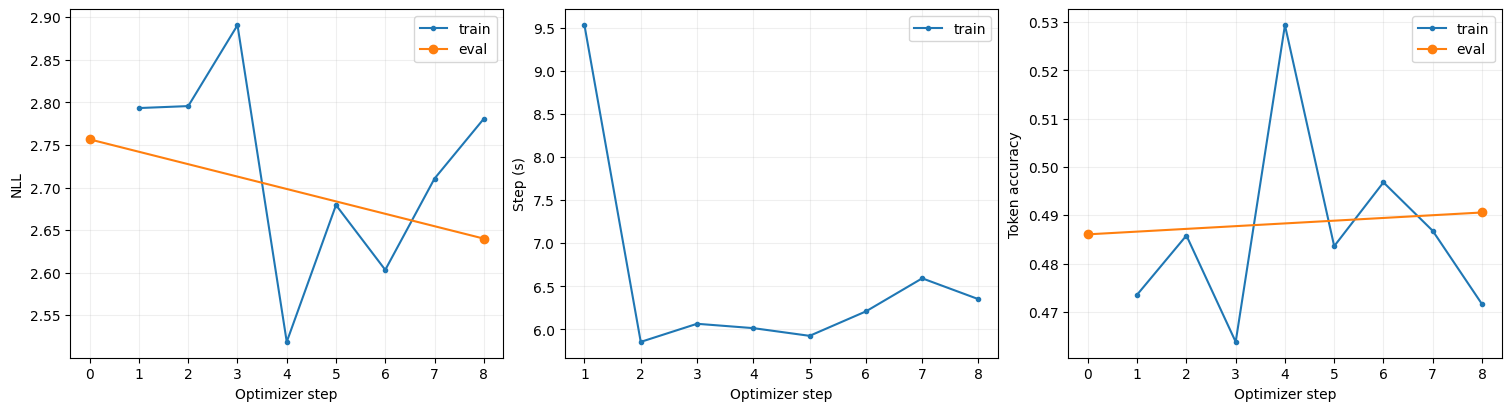

In [6]:
smoke = json.loads((HERE / 'slop_experiments/8_torchao_simpruning_optimization_2/torchao_sp_cached_smoke/training.json').read_text())
display(pd.DataFrame([{'stage':'before SP', **smoke['unpruned_before']},
                      {'stage':'after SP / before training', **smoke['before']},
                      {'stage':'after 8 training steps', **smoke['after']}]).set_index('stage')
        .filter(regex='eval_loss|eval_perplexity|eval_mean_token_accuracy'))
print({k:smoke[k] for k in ['steady_tokens_per_second', 'steady_samples_per_second',
                           'peak_allocated_GiB', 'finite_train_metrics', 'skipped_updates', 'adapter_check']})
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, key, ylabel in zip(axes, ['loss', 'step_seconds', 'mean_token_accuracy'],
                          ['NLL', 'Step (s)', 'Token accuracy']):
    rows = [r for r in smoke['history'] if key in r]
    ax.plot([r['step'] for r in rows], [r[key] for r in rows], marker='.', label='train')
    eval_rows = [r for r in smoke['history'] if 'eval_'+key in r]
    if eval_rows:
        ax.plot([r['step'] for r in eval_rows], [r['eval_'+key] for r in eval_rows], marker='o', label='eval')
    ax.set(xlabel='Optimizer step', ylabel=ylabel)
    ax.grid(alpha=.2)
    ax.legend()
plt.show()


## Применение

В `train_qwen_torchao_simpruning_fast.py` добавлен **опциональный** `--cache-bookkeeping`; прежний запуск без флага сохраняет прежнее поведение.

```bash
CUDA_VISIBLE_DEVICES=2 COMPUTE_DTYPE=fp16 .venv/bin/python -u \
  experiments/qlora/slop_experiments/train_qwen_torchao_simpruning_fast.py --cache-bookkeeping
```

По умолчанию это 100 шагов, результаты в `8_torchao_simpruning_optimization_2/torchao_sft_simpruning_cached`. Это команда для отдельного запуска, не результат этого короткого исследования.

Внутри подготовки достаточно `cache_parameter_iteration(model)` и `cache_flop_count(trainer, example_batch)` после установки обёрток/масок. Кэш хранит **ссылки на те же параметры**, а не копии весов. Число токенов в FLOP estimate продолжает браться из текущего batch. Сама оценка FLOPs остаётся исходной приблизительной формулой Trainer, а не точным подсчётом INT4/MoE операций.

Перед добавлением/удалением адаптеров, заменой Parameter, структурным pruning или перемещением, способным заменить параметры, восстановить методы через `restore_training_shortcuts(model, trainer)` и при необходимости построить кэш заново. Оптимизация `train()` предполагает управление train/eval через корневую модель, без независимого переключения дочерних модулей.

Другие пакеты, attention, RMSNorm, маски, precision и ядра не патчились. Сохранены все исходные результаты, включая серии, в которых общее время не улучшилось.
